In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [ ]:
url = "https://raw.githubusercontent.com/plotly/datasets/master/finance-charts-apple.csv"

df = pd.read_csv(url)

df.head()

,Date,AAPL.Open,AAPL.High,AAPL.Low,AAPL.Close,AAPL.Volume,AAPL.Adjusted,dn,mavg,up,direction
0,2015-02-17,127.489998,128.880005,126.919998,127.830002,63152400,122.905254,106.741052,117.927667,129.114281,Increasing
1,2015-02-18,127.629997,128.779999,127.449997,128.720001,44891700,123.760965,107.842423,118.940333,130.038244,Increasing
2,2015-02-19,128.479996,129.029999,128.330002,128.449997,37362400,123.501363,108.894245,119.889167,130.884089,Decreasing
3,2015-02-20,128.619995,129.500000,128.050003,129.500000,48948400,124.510914,109.785449,120.763500,131.741551,Increasing
4,2015-02-23,130.020004,133.000000,129.660004,133.000000,70974100,127.876074,110.372516,121.720167,133.067817,Increasing


In [ ]:
print(df.shape)
print(df.columns)
print(df.info())

(506, 11)
Index(['Date', 'AAPL.Open', 'AAPL.High', 'AAPL.Low', 'AAPL.Close',
       'AAPL.Volume', 'AAPL.Adjusted', 'dn', 'mavg', 'up', 'direction'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           506 non-null    object 
 1   AAPL.Open      506 non-null    float64
 2   AAPL.High      506 non-null    float64
 3   AAPL.Low       506 non-null    float64
 4   AAPL.Close     506 non-null    float64
 5   AAPL.Volume    506 non-null    int64  
 6   AAPL.Adjusted  506 non-null    float64
 7   dn             506 non-null    float64
 8   mavg           506 non-null    float64
 9   up             506 non-null    float64
 10  direction      506 non-null    object 
dtypes: float64(8), int64(1), object(2)
memory usage: 43.6+ KB
None


In [ ]:
df.describe()

,AAPL.Open,AAPL.High,AAPL.Low,AAPL.Close,AAPL.Volume,AAPL.Adjusted,dn,mavg,up
count,506.000000,506.000000,506.000000,506.000000,5.060000e+02,506.000000,506.000000,506.000000,506.000000
mean,112.935000,113.919447,111.942016,112.958340,4.317842e+07,110.459312,107.311385,112.739865,118.168345
std,11.287490,11.251892,11.263687,11.244744,1.985253e+07,10.537529,11.095804,10.595315,10.670752
min,90.000000,91.669998,89.470001,90.339996,1.147590e+07,89.008370,85.508858,94.047166,97.572721
25%,105.482500,106.349999,104.657501,105.672499,2.974240e+07,103.484803,97.011245,104.954875,111.052267
50%,112.889999,114.145001,111.800003,113.025002,3.747460e+07,110.821123,107.351628,112.799750,118.472542
75%,122.267498,123.497500,121.599998,122.179998,5.076395e+07,119.255457,114.812152,121.889416,128.515793
max,135.669998,136.270004,134.839996,135.509995,1.622063e+08,135.509995,127.289258,129.845000,138.805366


In [ ]:
print(df.isnull().sum())

Date             0
AAPL.Open        0
AAPL.High        0
AAPL.Low         0
AAPL.Close       0
AAPL.Volume      0
AAPL.Adjusted    0
dn               0
mavg             0
up               0
direction        0
dtype: int64


In [ ]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")

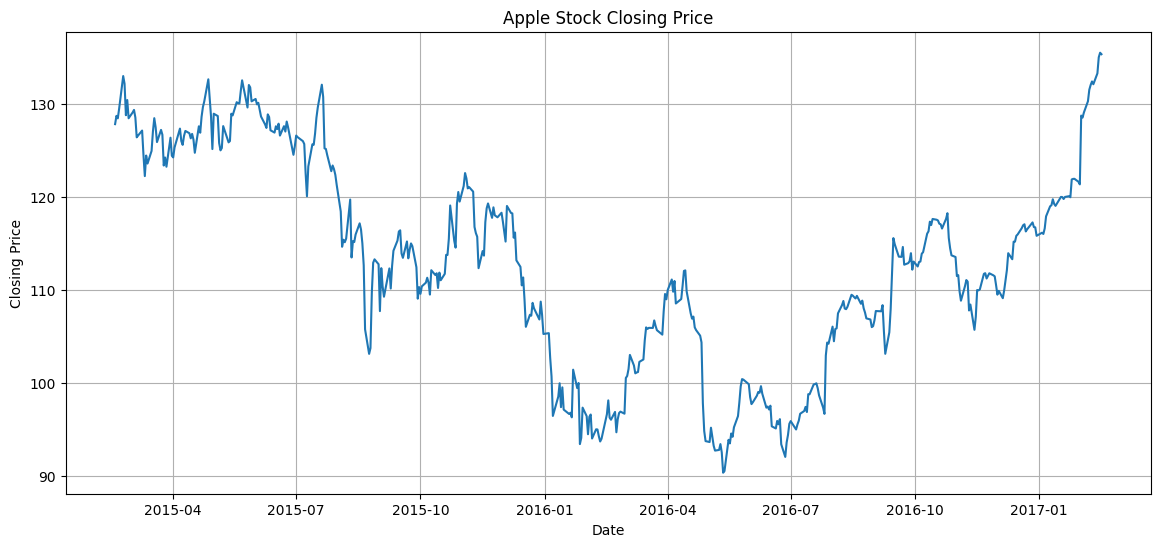

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["AAPL.Close"]
)

plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.title("Apple Stock Closing Price")
plt.grid(True)
plt.show()

In [ ]:
data = df[["AAPL.Close"]].values

In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(data)

print(scaled_data[:5])

[[0.8299758 ]
 [0.84967912]
 [0.84370161]
 [0.8669472 ]
 [0.94443225]]


In [ ]:
train_size = int(len(scaled_data) * 0.8)

train_data = scaled_data[:train_size]
test_data = scaled_data[train_size:]

print("Training Samples:", len(train_data))
print("Testing Samples:", len(test_data))

Training Samples: 404
Testing Samples: 102


In [ ]:
def create_sequences(dataset, time_step=60):
    X = []
    y = []

    for i in range(time_step, len(dataset)):
        X.append(dataset[i-time_step:i, 0])
        y.append(dataset[i, 0])

    return np.array(X), np.array(y)

In [ ]:
X_train, y_train = create_sequences(train_data, 60)

combined_data = np.concatenate(
    (train_data[-60:], test_data),
    axis=0
)

X_test, y_test = create_sequences(combined_data, 60)

print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)
print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (344, 60)
y_train Shape: (344,)
X_test Shape: (102, 60)
y_test Shape: (102,)


In [ ]:
X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

X_test = X_test.reshape(
    X_test.shape[0],
    X_test.shape[1],
    1
)

print(X_train.shape)
print(X_test.shape)

(344, 60, 1)
(102, 60, 1)


In [ ]:
model = keras.Sequential([
    layers.LSTM(
        50,
        return_sequences=True,
        input_shape=(X_train.shape[1], 1)
    ),

    layers.Dropout(0.2),

    layers.LSTM(
        50,
        return_sequences=False
    ),

    layers.Dropout(0.2),

    layers.Dense(25, activation="relu"),

    layers.Dense(1)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - loss: 0.1199 - val_loss: 0.0106
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0301 - val_loss: 0.0183
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0233 - val_loss: 0.0055
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0157 - val_loss: 0.0064
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0142 - val_loss: 0.0090


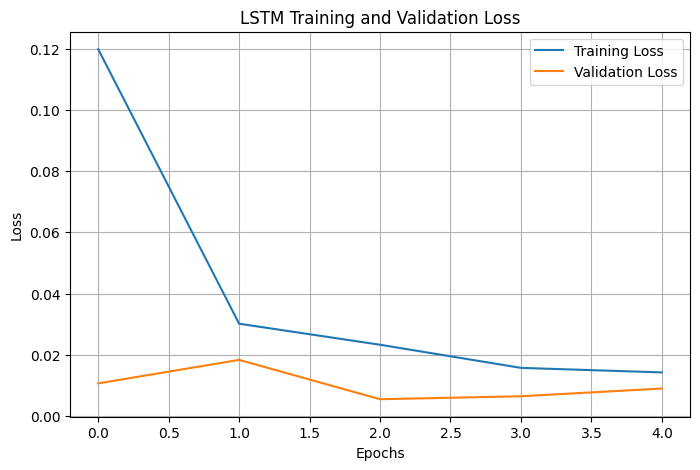

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
predictions = model.predict(X_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step


In [ ]:
predictions = scaler.inverse_transform(predictions)

actual_prices = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

In [ ]:
mse = mean_squared_error(actual_prices, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(actual_prices, predictions)

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("Mean Absolute Error:", mae)

Mean Squared Error: 27.350611801584026
Root Mean Squared Error: 5.22978123840606
Mean Absolute Error: 4.308923983345781


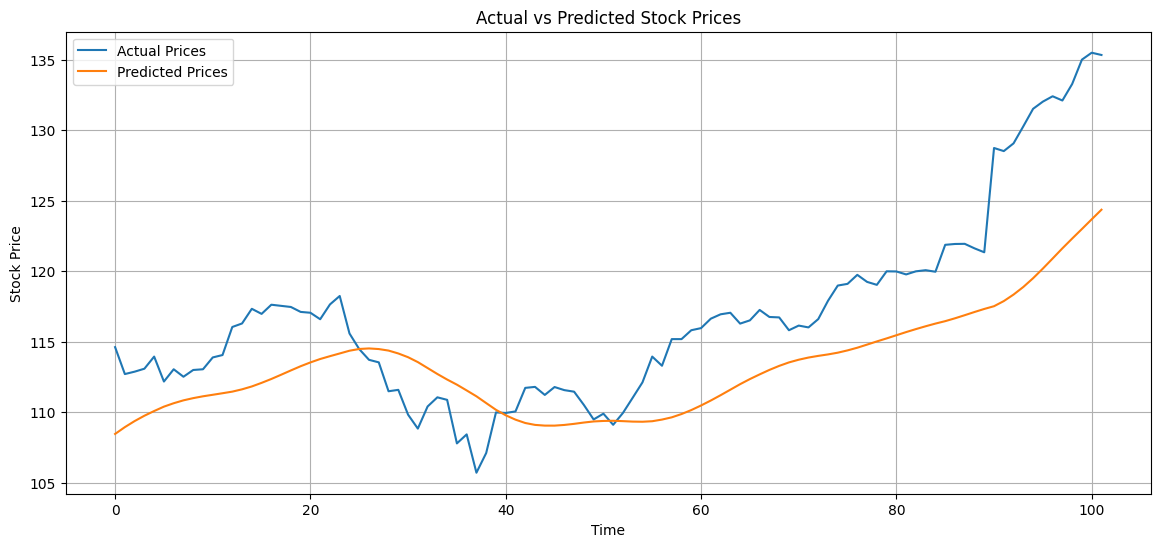

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    actual_prices,
    label="Actual Prices"
)

plt.plot(
    predictions,
    label="Predicted Prices"
)

plt.xlabel("Time")
plt.ylabel("Stock Price")
plt.title("Actual vs Predicted Stock Prices")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
results = pd.DataFrame({
    "Actual Price": actual_prices.flatten(),
    "Predicted Price": predictions.flatten()
})

results.head(20)

,Actual Price,Predicted Price
0,114.620003,108.461655
1,112.709999,108.944931
2,112.879997,109.374443
3,113.089996,109.753502
4,113.949997,110.087433
5,112.180000,110.399033
6,113.050003,110.640739
7,112.519997,110.845131
8,113.000000,111.002266
9,113.050003,111.132233


In [ ]:
last_60_days = scaled_data[-60:]

last_60_days = last_60_days.reshape(
    1,
    60,
    1
)

next_prediction = model.predict(last_60_days)

next_prediction = scaler.inverse_transform(
    next_prediction
)

print("Predicted Next Closing Price:", next_prediction[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Predicted Next Closing Price: 125.01934


In [ ]:
print("An LSTM-based time-series forecasting model was developed.")
print("The model used the previous 60 stock prices to predict the next closing price.")
print("The data was normalized using MinMaxScaler.")
print("The model performance was evaluated using MSE, RMSE and MAE.")
print("Actual and predicted stock prices were visualized using a comparison graph.")

An LSTM-based time-series forecasting model was developed.
The model used the previous 60 stock prices to predict the next closing price.
The data was normalized using MinMaxScaler.
The model performance was evaluated using MSE, RMSE and MAE.
Actual and predicted stock prices were visualized using a comparison graph.
